# Credit Card Customer Churn Analysis
### Identifying At-Risk Customers and Retention Strategies

**Author:** Mohammad Adhil  
**Tools:** Python (pandas, matplotlib, seaborn)  
**Dataset:** Credit card customers of a bank (10,127 customers, 21 columns)

## Business Problem
Winning a new credit card customer costs far more than keeping an existing one. The bank is losing customers (churn) and wants to know who is leaving, what warning signs come first, and who is likely to leave next, so the retention team can act early.

## Questions This Project Answers
1. What is the overall churn rate, and why does it matter?
2. Which customer segments churn the most?
3. Which customer behaviours signal that someone is about to leave?
4. Are high-value customers leaving more or less than others?
5. Which customers are at high, medium or low risk, and what should the bank do for each group?

## Step 1: Setup and loading the data

In [1]:
# pandas: for working with tables of data
import pandas as pd

# matplotlib and seaborn: for making charts
import matplotlib.pyplot as plt
import seaborn as sns

# Clean, professional look for all charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Show all columns when we print a table
pd.set_option("display.max_columns", None)

print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
# Load the original data (the original file is never edited)
raw = pd.read_csv("../data/BankChurners.csv")

# Look at the first 5 customers
raw.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


In [3]:
# How many rows (customers) and columns?
print("Rows, Columns:", raw.shape)

# Column names, data types, and non-null counts
raw.info()

Rows, Columns: (10127, 21)
<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CLIENTNUM                 10127 non-null  int64  
 1   Attrition_Flag            10127 non-null  str    
 2   Customer_Age              10127 non-null  int64  
 3   Gender                    10127 non-null  str    
 4   Dependent_count           10127 non-null  int64  
 5   Education_Level           10127 non-null  str    
 6   Marital_Status            10127 non-null  str    
 7   Income_Category           10127 non-null  str    
 8   Card_Category             10127 non-null  str    
 9   Months_on_book            10127 non-null  int64  
 10  Total_Relationship_Count  10127 non-null  int64  
 11  Months_Inactive_12_mon    10127 non-null  int64  
 12  Contacts_Count_12_mon     10127 non-null  int64  
 13  Credit_Limit              10127 non-null  flo

## Step 2: Data understanding and cleaning

In [4]:
# Work on a copy so the original data stays untouched
df = raw.copy()

# Standardise column names: lowercase
df.columns = df.columns.str.lower()

# Rename long or confusing columns to clearer names
df = df.rename(columns={
    "clientnum": "customer_id",
    "attrition_flag": "customer_status",
    "months_inactive_12_mon": "months_inactive",
    "contacts_count_12_mon": "contacts_count",
    "total_relationship_count": "products_held",
    "months_on_book": "tenure_months",
    "avg_open_to_buy": "available_credit",
    "total_revolving_bal": "revolving_balance",
    "total_trans_amt": "trans_amount",
    "total_trans_ct": "trans_count",
    "total_amt_chng_q4_q1": "amt_change_q4_q1",
    "total_ct_chng_q4_q1": "ct_change_q4_q1",
    "avg_utilization_ratio": "utilization_ratio"
})

df.columns.tolist()

['customer_id', 'customer_status', 'customer_age', 'gender', 'dependent_count', 'education_level', 'marital_status', 'income_category', 'card_category', 'tenure_months', 'products_held', 'months_inactive', 'contacts_count', 'credit_limit', 'revolving_balance', 'available_credit', 'amt_change_q4_q1', 'trans_amount', 'trans_count', 'ct_change_q4_q1', 'utilization_ratio']

In [5]:
# Duplicate rows and duplicate customer IDs
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

# Missing values (blank cells)
print("\nMissing values in the whole table:", df.isnull().sum().sum())

Duplicate rows: 0
Duplicate customer IDs: 0

Missing values in the whole table: 0


In [6]:
# "Unknown" is also missing information, but Python does not count it as missing.
# Count the "Unknown" labels in the three columns that have them
unknown_counts = (df[["education_level", "marital_status", "income_category"]] == "Unknown").sum()
print(unknown_counts)

# The same as a percentage of all customers
unknown_pct = (df[["education_level", "marital_status", "income_category"]] == "Unknown").mean() * 100
print()
print(unknown_pct.round(1))

education_level    1519
marital_status      749
income_category    1112
dtype: int64

education_level    15.0
marital_status      7.4
income_category    11.0
dtype: float64


**Decision:** the "Unknown" labels are **kept** as their own category instead of deleting those customers. Removing them would throw away up to 1 in 6 customers and could bias the results.

In [7]:
# Remove the $ sign from the income labels.
# (Charts treat text between two $ signs as a math formula, which garbles the labels.)
df["income_category"] = df["income_category"].str.replace("$", "", regex=False)

df["income_category"].value_counts()

income_category
Less than 40K    3561
40K - 60K        1790
80K - 120K       1535
60K - 80K        1402
Unknown          1112
120K +            727
Name: count, dtype: int64

In [8]:
# Create the churn flag: 1 = customer left, 0 = still a customer.
# Later, the average of this column = the churn rate.
df["churn_flag"] = (df["customer_status"] == "Attrited Customer").astype(int)

print(df["churn_flag"].value_counts())
print("\nOverall churn rate:", round(df["churn_flag"].mean() * 100, 1), "%")

churn_flag
0    8500
1    1627
Name: count, dtype: int64

Overall churn rate: 16.1 %


In [9]:
# Check for outliers: summary numbers first
num_cols = ["customer_age", "credit_limit", "trans_amount", "trans_count",
            "utilization_ratio", "amt_change_q4_q1", "ct_change_q4_q1"]

df[num_cols].describe().round(2)

,customer_age,credit_limit,trans_amount,trans_count,utilization_ratio,amt_change_q4_q1,ct_change_q4_q1
count,10127.00,10127.00,10127.00,10127.00,10127.00,10127.00,10127.00
mean,46.33,8631.95,4404.09,64.86,0.27,0.76,0.71
std,8.02,9088.78,3397.13,23.47,0.28,0.22,0.24
min,26.00,1438.30,510.00,10.00,0.00,0.00,0.00
25%,41.00,2555.00,2155.50,45.00,0.02,0.63,0.58
50%,46.00,4549.00,3899.00,67.00,0.18,0.74,0.70
75%,52.00,11067.50,4741.00,81.00,0.50,0.86,0.82
max,73.00,34516.00,18484.00,139.00,1.00,3.40,3.71


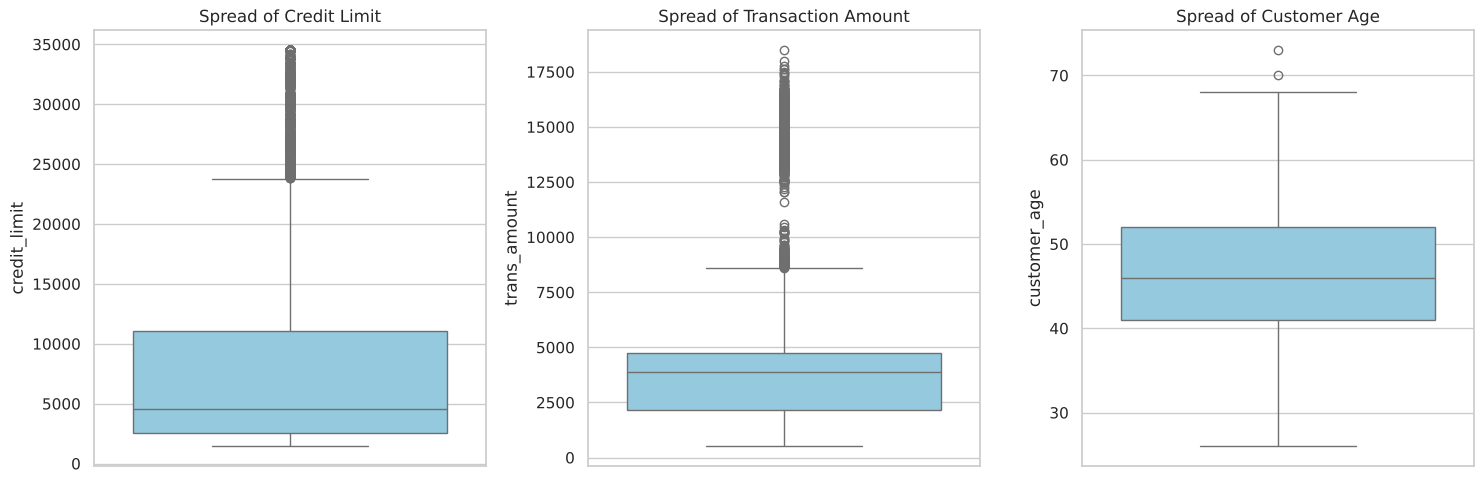

In [10]:
# Box plots: dots beyond the whiskers are outliers
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(y=df["credit_limit"], ax=axes[0], color="skyblue")
axes[0].set_title("Spread of Credit Limit")

sns.boxplot(y=df["trans_amount"], ax=axes[1], color="skyblue")
axes[1].set_title("Spread of Transaction Amount")

sns.boxplot(y=df["customer_age"], ax=axes[2], color="skyblue")
axes[2].set_title("Spread of Customer Age")

plt.tight_layout()
plt.show()

**Decision:** the high values in credit limit and transaction amount are genuine high-value customers, not errors, so they are **kept**. Removing them would hide the customers the bank most wants to retain. Customer ages (26 to 73) look normal.

## Step 3: Feature engineering
New columns made from existing ones, so the data is easier to analyse.

In [11]:
# Age groups
df["age_group"] = pd.cut(
    df["customer_age"],
    bins=[0, 35, 45, 55, 100],
    labels=["Under 36", "36-45", "46-55", "56+"]
)

df["age_group"].value_counts().sort_index()

age_group
Under 36     919
36-45       3742
46-55       4135
56+         1331
Name: count, dtype: int64

In [12]:
# Tenure groups (how long the customer has been with the bank)
df["tenure_group"] = pd.cut(
    df["tenure_months"],
    bins=[0, 24, 36, 48, 100],
    labels=["Up to 2 yrs", "2-3 yrs", "3-4 yrs", "4+ yrs"]
)

df["tenure_group"].value_counts().sort_index()

tenure_group
Up to 2 yrs     847
2-3 yrs        5418
3-4 yrs        3207
4+ yrs          655
Name: count, dtype: int64

In [13]:
# Average amount spent each time the customer uses the card
df["avg_trans_value"] = (df["trans_amount"] / df["trans_count"]).round(2)

df["avg_trans_value"].describe()

count    10127.000000
mean        62.612769
std         26.404131
min         19.140000
25%         47.515000
50%         55.790000
75%         65.475000
max        190.190000
Name: avg_trans_value, dtype: float64

In [14]:
# 1 = inactive for 3 or more months in the last year, 0 = not
df["inactive_flag"] = (df["months_inactive"] >= 3).astype(int)

df["inactive_flag"].value_counts()

inactive_flag
0    5544
1    4583
Name: count, dtype: int64

## Step 4A: Business questions 1 and 2
We compare churn **rates** inside each group, not raw counts. Only about 16% of customers churned, and large groups always contain more churners.

### Question 1: How big is the churn problem?

In [15]:
total = len(df)                       # total customers
churned = df["churn_flag"].sum()      # customers who left
rate = churned / total * 100          # churn rate in %

print("Total customers:", total)
print("Churned customers:", churned)
print("Churn rate:", round(rate, 1), "%")

Total customers: 10127
Churned customers: 1627
Churn rate: 16.1 %


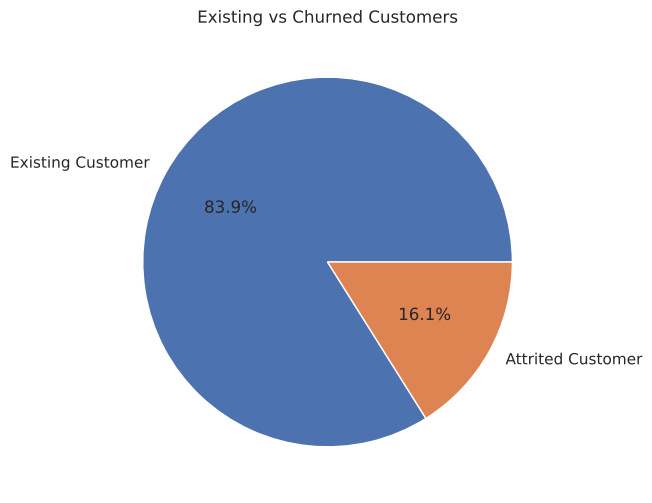

In [16]:
# Pie chart: existing vs churned customers
df["customer_status"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Existing vs Churned Customers")
plt.ylabel("")
plt.savefig("../images/churn_overview.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# How much does it matter in money terms?
total_spend = df["trans_amount"].sum()
lost_spend = df[df["churn_flag"] == 1]["trans_amount"].sum()
print("Share of spending from churned customers:", round(lost_spend / total_spend * 100, 1), "%")

total_limit = df["credit_limit"].sum()
lost_limit = df[df["churn_flag"] == 1]["credit_limit"].sum()
print("Share of credit limit held by churned customers:", round(lost_limit / total_limit * 100, 1), "%")

Share of spending from churned customers: 11.3 %
Share of credit limit held by churned customers: 15.1 %


**Takeaway:** about 1 in 6 customers has left. They accounted for roughly 11% of all card spending and 15% of the credit limit, so churn is a revenue problem, not just a customer-count problem.

### Question 2: Which customer groups churn the most?

age_group
Under 36    13.3
36-45       16.2
46-55       16.6
56+         15.9
Name: churn_flag, dtype: float64


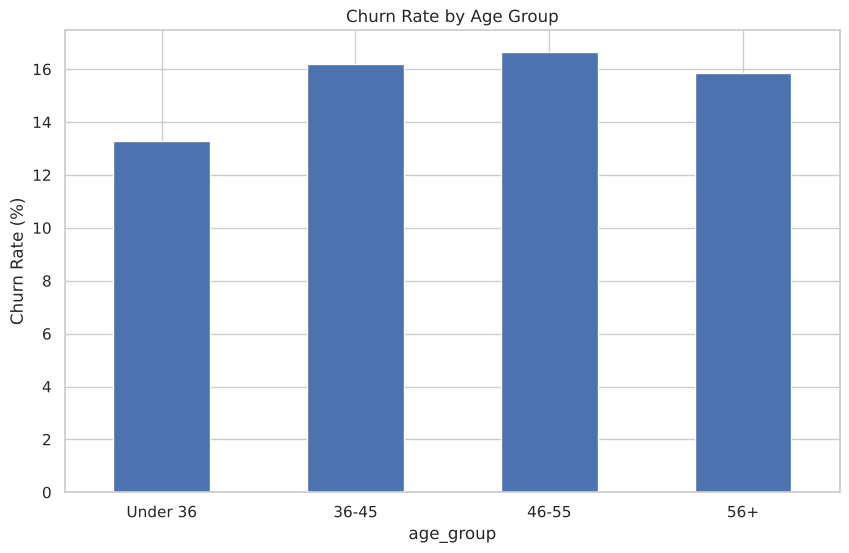

In [18]:
# Churn rate by age group
age_rate = df.groupby("age_group")["churn_flag"].mean() * 100

age_rate.plot(kind="bar")
plt.title("Churn Rate by Age Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

print(age_rate.round(1))

gender
F    17.4
M    14.6
Name: churn_flag, dtype: float64


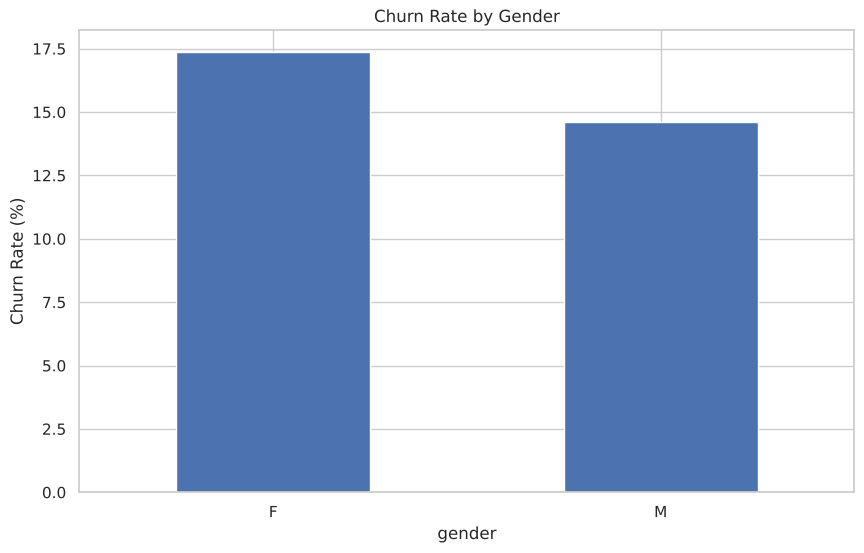

In [19]:
# Churn rate by gender
gender_rate = df.groupby("gender")["churn_flag"].mean() * 100

gender_rate.plot(kind="bar")
plt.title("Churn Rate by Gender")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

print(gender_rate.round(1))

income_category
Less than 40K    17.2
40K - 60K        15.1
60K - 80K        13.5
80K - 120K       15.8
120K +           17.3
Unknown          16.8
Name: churn_flag, dtype: float64


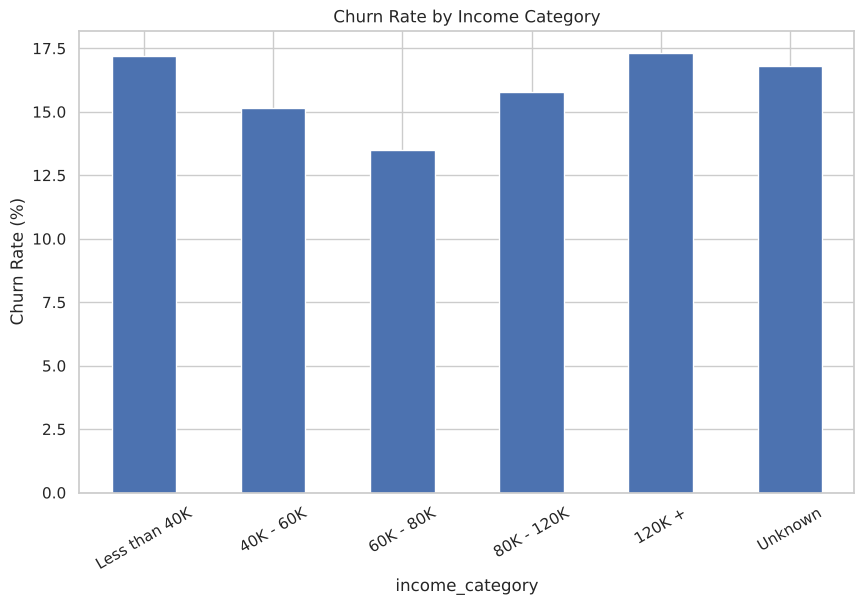

In [20]:
# Churn rate by income (reindex puts the groups in a sensible order)
income_rate = df.groupby("income_category")["churn_flag"].mean() * 100
income_rate = income_rate.reindex(["Less than 40K", "40K - 60K", "60K - 80K", "80K - 120K", "120K +", "Unknown"])

income_rate.plot(kind="bar")
plt.title("Churn Rate by Income Category")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.show()

print(income_rate.round(1))

card_category
Blue        16.1
Silver      14.8
Gold        18.1
Platinum    25.0
Name: churn_flag, dtype: float64

Customers per card type:
card_category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64


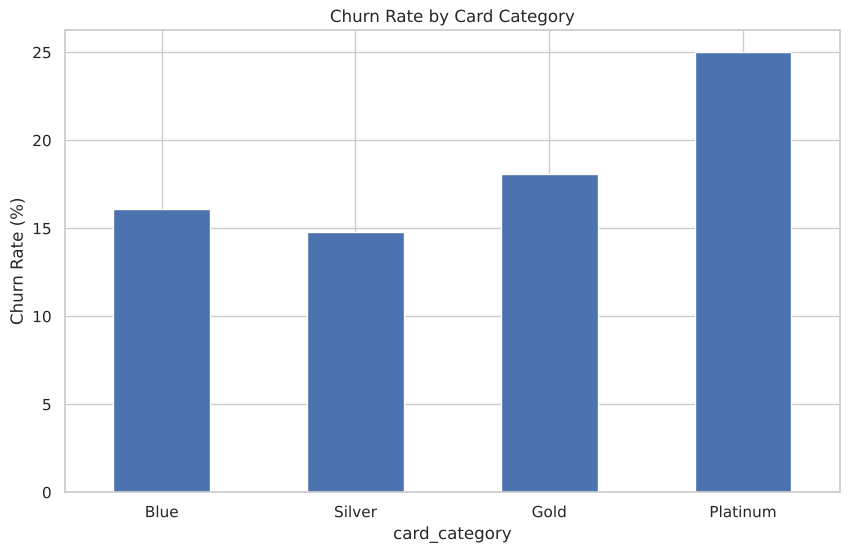

In [21]:
# Churn rate by card category
card_rate = df.groupby("card_category")["churn_flag"].mean() * 100
card_rate = card_rate.reindex(["Blue", "Silver", "Gold", "Platinum"])

card_rate.plot(kind="bar")
plt.title("Churn Rate by Card Category")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

print(card_rate.round(1))
print()
print("Customers per card type:")
print(df["card_category"].value_counts())

education_level
College          15.2
Doctorate        21.1
Graduate         15.6
High School      15.2
Post-Graduate    17.8
Uneducated       15.9
Unknown          16.9
Name: churn_flag, dtype: float64


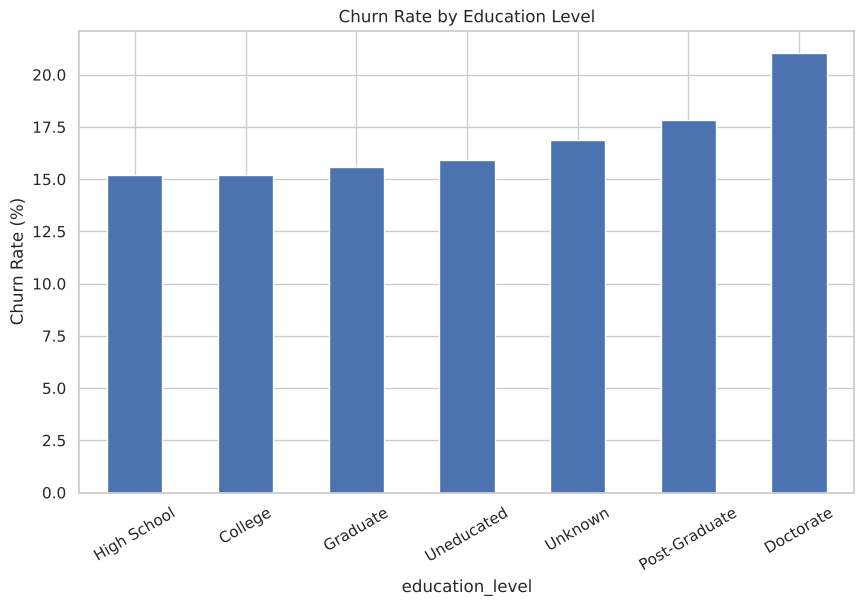

In [22]:
# Churn rate by education level
edu_rate = df.groupby("education_level")["churn_flag"].mean() * 100

edu_rate.sort_values().plot(kind="bar")
plt.title("Churn Rate by Education Level")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.show()

print(edu_rate.round(1))

marital_status
Divorced    16.2
Married     15.1
Single      16.9
Unknown     17.2
Name: churn_flag, dtype: float64


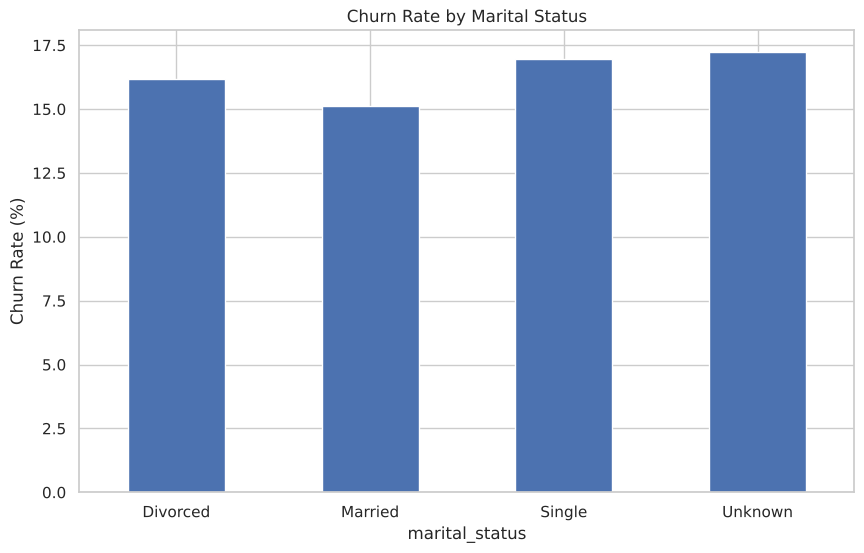

In [23]:
# Churn rate by marital status
marital_rate = df.groupby("marital_status")["churn_flag"].mean() * 100

marital_rate.plot(kind="bar")
plt.title("Churn Rate by Marital Status")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

print(marital_rate.round(1))

**Takeaway:** demographics explain little. Most groups sit close to the overall 16.1%. Women churn a little more than men (17.4% vs 14.6%). Platinum cardholders show the highest rate (25.0%) but there are only 20 of them, and Doctorate holders (451 customers) show 21.1%, so treat these two as "worth watching", not firm conclusions. Behaviour is where the stronger signals are (next section).

## Step 4B: Business questions 3 and 4
### Question 3: Do customer behaviours warn us that someone is about to leave?

months_inactive
0    51.7
1     4.5
2    15.4
3    21.5
4    29.9
5    18.0
6    15.3
Name: churn_flag, dtype: float64

Customers per value (0 months has only a few customers, so ignore that bar):
months_inactive
0      29
1    2233
2    3282
3    3846
4     435
5     178
6     124
Name: count, dtype: int64


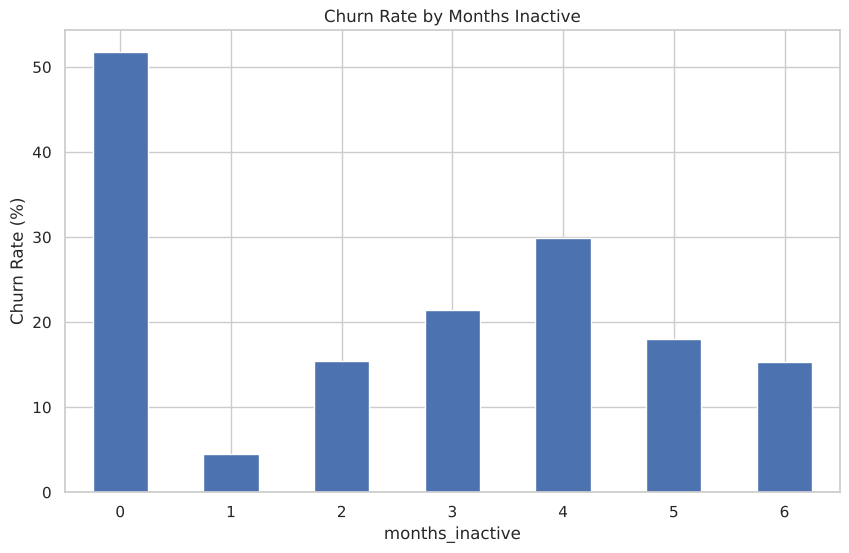

In [24]:
# Churn rate by months inactive
inactive_rate = df.groupby("months_inactive")["churn_flag"].mean() * 100

inactive_rate.plot(kind="bar")
plt.title("Churn Rate by Months Inactive")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.savefig("../images/churn_by_inactivity.png", dpi=150, bbox_inches="tight")
plt.show()

print(inactive_rate.round(1))
print()
print("Customers per value (0 months has only a few customers, so ignore that bar):")
print(df["months_inactive"].value_counts().sort_index())

In [25]:
# Check the 3-month inactive flag made in Step 3
flag_rate = df.groupby("inactive_flag")["churn_flag"].mean() * 100
print(flag_rate.round(1))

inactive_flag
0    11.2
1    22.0
Name: churn_flag, dtype: float64


contacts_count
0      1.8
1      7.2
2     12.5
3     20.1
4     22.6
5     33.5
6    100.0
Name: churn_flag, dtype: float64

Customers per value (6 contacts has only a few customers):
contacts_count
0     399
1    1499
2    3227
3    3380
4    1392
5     176
6      54
Name: count, dtype: int64


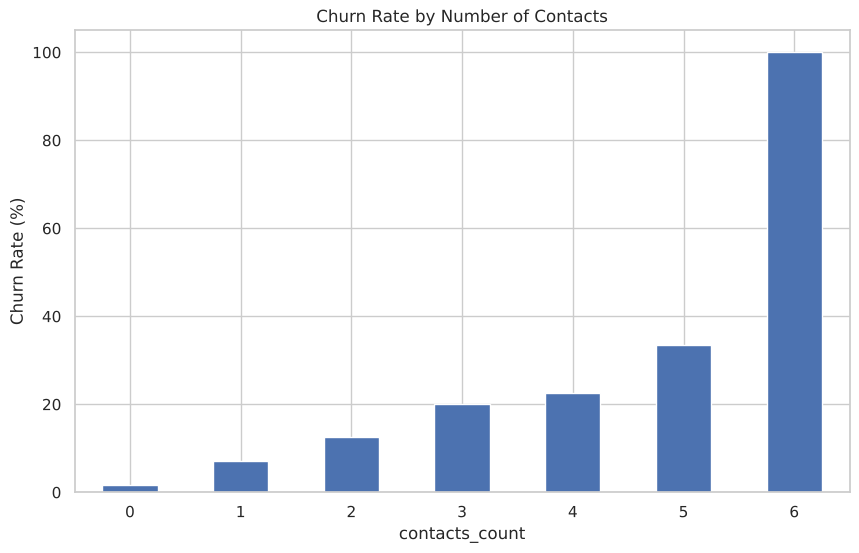

In [26]:
# Churn rate by number of contacts with the bank
contact_rate = df.groupby("contacts_count")["churn_flag"].mean() * 100

contact_rate.plot(kind="bar")
plt.title("Churn Rate by Number of Contacts")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.savefig("../images/churn_by_contacts.png", dpi=150, bbox_inches="tight")
plt.show()

print(contact_rate.round(1))
print()
print("Customers per value (6 contacts has only a few customers):")
print(df["contacts_count"].value_counts().sort_index())

products_held
1    25.6
2    27.8
3    17.4
4    11.8
5    12.0
6    10.5
Name: churn_flag, dtype: float64


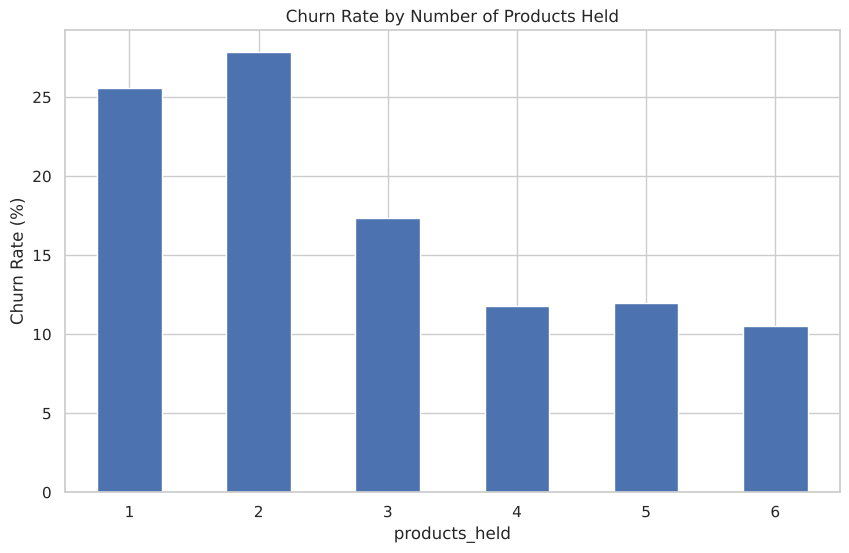

In [27]:
# Churn rate by number of products held
products_rate = df.groupby("products_held")["churn_flag"].mean() * 100

products_rate.plot(kind="bar")
plt.title("Churn Rate by Number of Products Held")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.savefig("../images/churn_by_products.png", dpi=150, bbox_inches="tight")
plt.show()

print(products_rate.round(1))

trans_group
Up to 40    31.5
41-60       37.0
61-80        5.8
81-100       1.6
Over 100     0.0
Name: churn_flag, dtype: float64


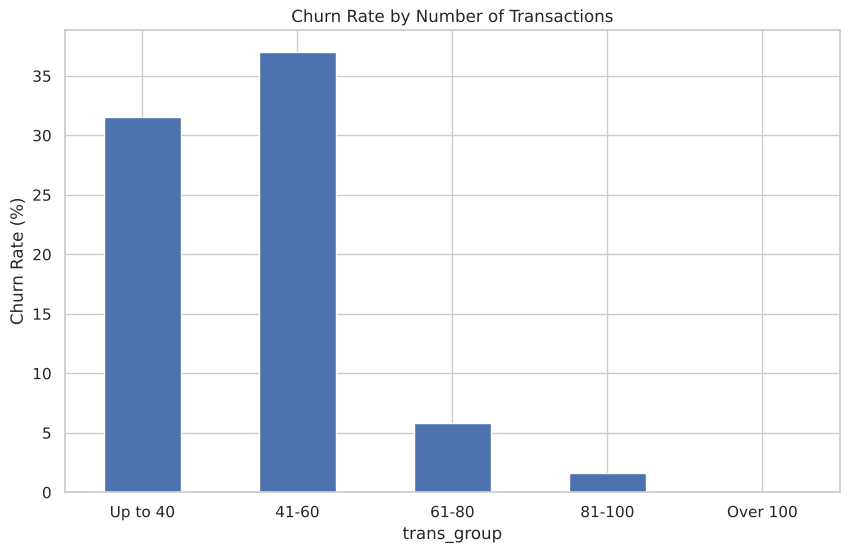

In [28]:
# Group customers by number of transactions, then check churn in each group
df["trans_group"] = pd.cut(
    df["trans_count"],
    bins=[0, 40, 60, 80, 100, 200],
    labels=["Up to 40", "41-60", "61-80", "81-100", "Over 100"]
)

trans_rate = df.groupby("trans_group")["churn_flag"].mean() * 100

trans_rate.plot(kind="bar")
plt.title("Churn Rate by Number of Transactions")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.savefig("../images/churn_by_transactions.png", dpi=150, bbox_inches="tight")
plt.show()

print(trans_rate.round(1))

In [29]:
# Average behaviour: churned vs existing customers
df.groupby("customer_status")[["trans_count", "trans_amount", "utilization_ratio"]].mean().round(2)

,trans_count,trans_amount,utilization_ratio
customer_status,,,
Attrited Customer,44.93,3095.03,0.16
Existing Customer,68.67,4654.66,0.30


**Takeaway:** behaviour predicts churn far better than demographics. Low transaction counts, inactivity, repeated contacts with the bank and holding few products are all linked to higher churn. These are "early warning signs", not proven causes: a customer who has already decided to leave may use the card less first.

### Question 4: Do high-value customers leave more or less?

limit_group
Under 2.5K    20.9
2.5K-5K       14.3
5K-10K        15.0
10K-20K       14.4
Over 20K      14.6
Name: churn_flag, dtype: float64


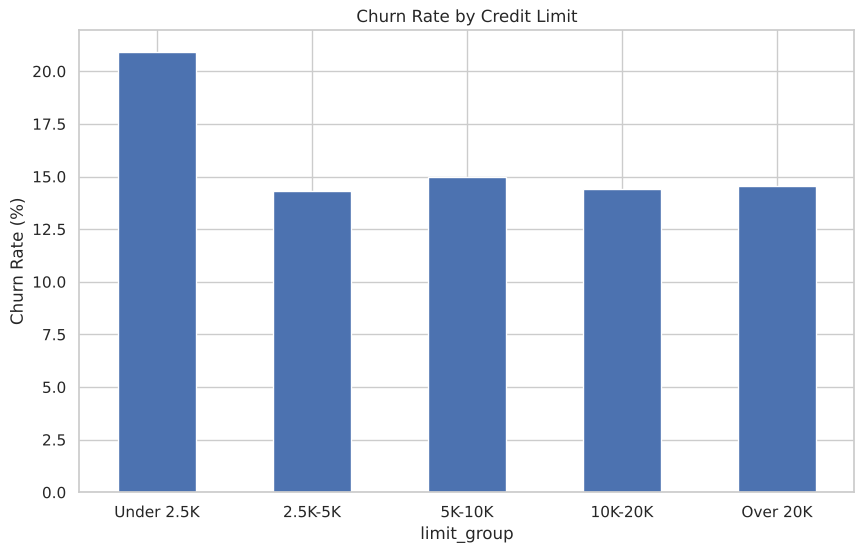

In [30]:
# Group customers by credit limit
df["limit_group"] = pd.cut(
    df["credit_limit"],
    bins=[0, 2500, 5000, 10000, 20000, 40000],
    labels=["Under 2.5K", "2.5K-5K", "5K-10K", "10K-20K", "Over 20K"]
)

limit_rate = df.groupby("limit_group")["churn_flag"].mean() * 100

limit_rate.plot(kind="bar")
plt.title("Churn Rate by Credit Limit")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

print(limit_rate.round(1))

spend_group
Under 2.5K    30.8
2.5K-5K        7.5
5K-10K        21.8
Over 10K       1.3
Name: churn_flag, dtype: float64

Customers per spending group:
spend_group
Under 2.5K    3236
2.5K-5K       5004
5K-10K        1130
Over 10K       757
Name: count, dtype: int64


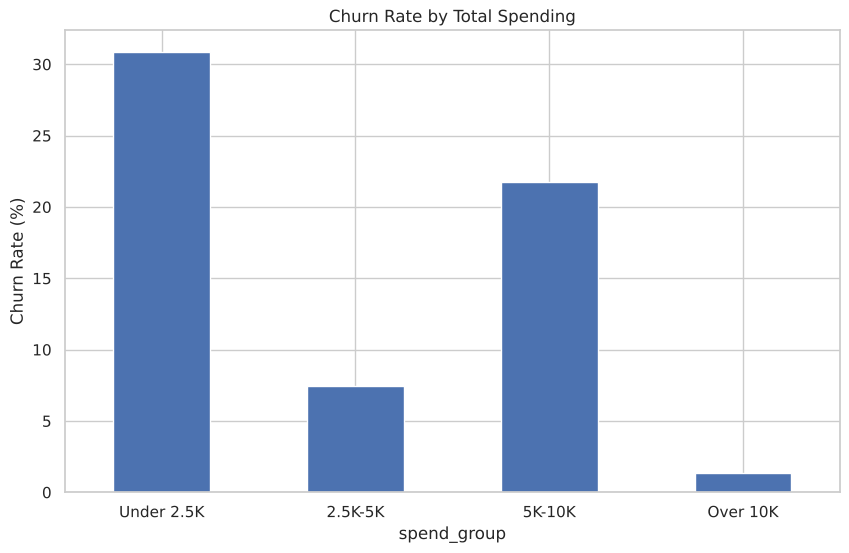

In [31]:
# Group customers by total spending
df["spend_group"] = pd.cut(
    df["trans_amount"],
    bins=[0, 2500, 5000, 10000, 20000],
    labels=["Under 2.5K", "2.5K-5K", "5K-10K", "Over 10K"]
)

spend_rate = df.groupby("spend_group")["churn_flag"].mean() * 100

spend_rate.plot(kind="bar")
plt.title("Churn Rate by Total Spending")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

print(spend_rate.round(1))
print()
print("Customers per spending group:")
print(df["spend_group"].value_counts().sort_index())

**Takeaway:** the biggest spenders (over 10K) almost never leave. But the 5K-10K spending group churns well above average, and customers with a credit limit under 2.5K also churn more. The picture is mixed, not simply "high value = loyal".

## Step 5: Rule-based risk segmentation
Each customer gets **1 point for every warning sign** found in Step 4B:

| Warning sign | Rule |
|---|---|
| Low card use | 60 transactions or fewer |
| Inactive | 3 or more months inactive |
| Many bank contacts | 3 or more contacts |
| Few products | 1 or 2 products |

No machine learning is used, so a manager can see exactly why a customer is flagged.

In [32]:
# 1 = customer shows this warning sign, 0 = does not
df["low_trans_flag"] = (df["trans_count"] <= 60).astype(int)
df["high_contact_flag"] = (df["contacts_count"] >= 3).astype(int)
df["few_products_flag"] = (df["products_held"] <= 2).astype(int)
# (inactive_flag was already made in Step 3)

print("Low transactions:", df["low_trans_flag"].sum())
print("Inactive 3+ months:", df["inactive_flag"].sum())
print("3+ contacts:", df["high_contact_flag"].sum())
print("1-2 products:", df["few_products_flag"].sum())

Low transactions: 4047
Inactive 3+ months: 4583
3+ contacts: 5002
1-2 products: 2153


In [33]:
# Risk score = number of warning signs (0 to 4)
df["risk_score"] = (df["low_trans_flag"] + df["inactive_flag"]
                    + df["high_contact_flag"] + df["few_products_flag"])

df["risk_score"].value_counts().sort_index()

risk_score
0    1332
1    3664
2    3483
3    1437
4     211
Name: count, dtype: int64

risk_score
0     0.9
1     5.1
2    16.8
3    44.5
4    95.7
Name: churn_flag, dtype: float64


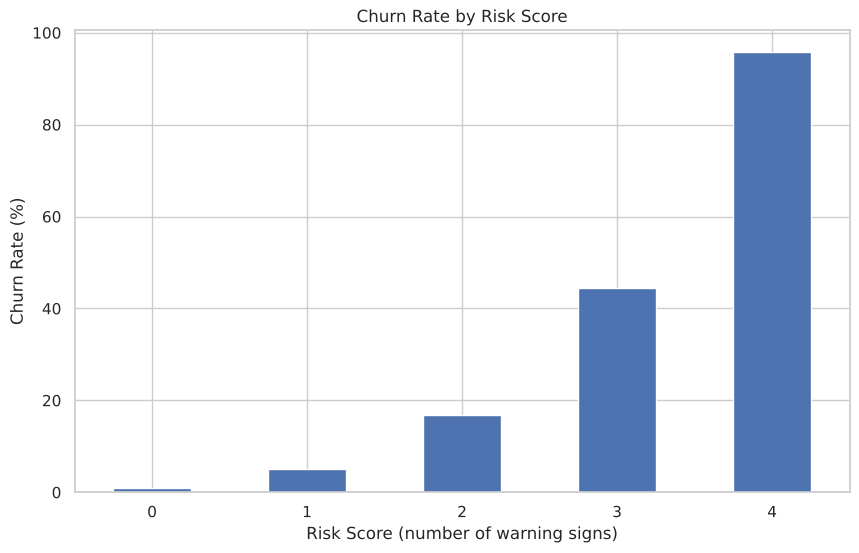

In [34]:
# Does a higher score really mean more churn?
score_rate = df.groupby("risk_score")["churn_flag"].mean() * 100

score_rate.plot(kind="bar")
plt.title("Churn Rate by Risk Score")
plt.xlabel("Risk Score (number of warning signs)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.savefig("../images/churn_by_risk_score.png", dpi=150, bbox_inches="tight")
plt.show()

print(score_rate.round(1))

In [35]:
# Group scores into Low (0-1), Medium (2) and High (3-4)
df["risk_level"] = pd.cut(
    df["risk_score"],
    bins=[-1, 1, 2, 4],
    labels=["Low", "Medium", "High"]
)

df["risk_level"].value_counts()

risk_level
Low       4996
Medium    3483
High      1648
Name: count, dtype: int64

risk_level
Low        4.0
Medium    16.8
High      51.1
Name: churn_flag, dtype: float64


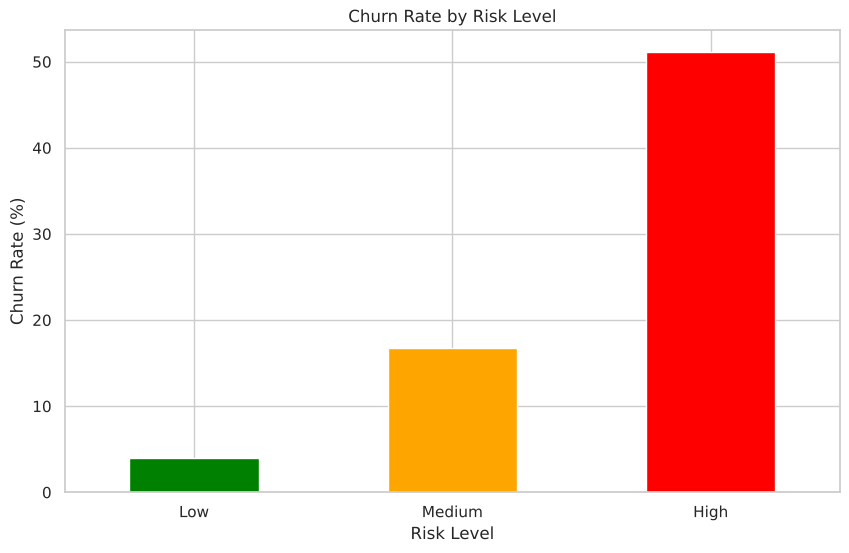

In [36]:
# Churn rate for each risk level
level_rate = df.groupby("risk_level")["churn_flag"].mean() * 100

level_rate.plot(kind="bar", color=["green", "orange", "red"])
plt.title("Churn Rate by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.savefig("../images/churn_by_risk_level.png", dpi=150, bbox_inches="tight")
plt.show()

print(level_rate.round(1))

In [37]:
# How many of the customers who left were in the High risk group?
churned_in_high = df[(df["risk_level"] == "High") & (df["churn_flag"] == 1)].shape[0]
total_churned = df["churn_flag"].sum()

print("Customers in High risk group:", (df["risk_level"] == "High").sum())
print("Churned customers in High group:", churned_in_high)
print("Share of all churners:", round(churned_in_high / total_churned * 100, 1), "%")

Customers in High risk group: 1648
Churned customers in High group: 842
Share of all churners: 51.8 %


**Takeaway:** churn rises steadily with each extra warning sign. The High risk group is about 16% of customers but contains about half of all churners, so a retention team can focus on those customers first.

## Step 6: Key insights

1. **About 1 in 6 customers has left, and it costs the bank revenue.** 1,627 of 10,127 customers (16.1%) churned. They accounted for 11.3% of all card spending and held 15.1% of total credit limit.
2. **Who a customer is matters much less than how they use the card.** Churn barely differs by age (13.3% to 16.6%), education, marital status or income.
3. **Low card usage is the strongest warning sign.** Customers with 60 or fewer transactions churn at about 31% to 37%, versus under 6% for those with more. Churned customers averaged 44.9 transactions against 68.7.
4. **Inactivity and repeated contacts are early warnings.** Inactive 3+ months: 22.0% churn vs 11.2%. Churn rises from 1.8% with no contacts to 33.5% with five.
5. **Fewer products means a higher chance of leaving.** 1 or 2 products: 25.6% to 27.8% churn. 4 to 6 products: about 11%.
6. **The biggest spenders are loyal, but a valuable middle group is leaking.** Spending over 10K: 1.3% churn. The 5K to 10K band churns at 21.8%.
7. **A simple risk score finds half of all churners in a small group.** The High risk group (1,648 customers) churns at 51.1% and holds 842 of the 1,627 churners (51.8%). The Low risk group churns at only 4.0%.

**Limitations:** the data is a single snapshot with no dates, so these are patterns, not proven causes. The risk rules were built and checked on the same data, so results on new customers would likely be weaker. Some groups are very small (20 Platinum customers, 54 customers with 6 contacts).

## Step 7: Business recommendations

1. **Build a monthly High risk call list.** The 1,648 High risk customers hold about half of all churners. Measure: churn rate of this group before and after.
2. **Re-activate drifting customers.** Trigger a nudge or reward offer when card usage drops or a customer is inactive for 3+ months. Measure: change in transaction count after the offer.
3. **Fix the causes of repeated contacts.** Escalate customers with 3+ contacts for first-contact resolution and review why they contact the bank. Measure: churn rate of customers with 3+ contacts.
4. **Cross-sell a second or third product** to customers holding only 1 or 2, starting with Medium risk. Measure: share who take a second product and their later churn rate.
5. **Protect the 5K to 10K spenders** with a personal offer or credit limit review, and review the experience of customers with limits under 2.5K. Measure: churn in these groups over two quarters.

| Risk level | Action |
|---|---|
| High | Personal call and retention offer, escalate open complaints |
| Medium | Automatic nudges, rewards for card use, cross-sell |
| Low | No special action, keep service quality |

Any action should be piloted on a small group first and compared with a similar group that did not receive it.

In [38]:
# "What if" example. ASSUMPTION (not a result): the retention team keeps 10% of High risk churners.
save_rate = 0.10

churned_in_high = df[(df["risk_level"] == "High") & (df["churn_flag"] == 1)].shape[0]
saved = churned_in_high * save_rate

print("Churners in High risk group:", churned_in_high)
print("Customers kept at a 10% save rate:", round(saved))

Churners in High risk group: 842
Customers kept at a 10% save rate: 84


## Step 8: Export the data for Power BI
A tidy file for building a dashboard.

In [39]:
# Power BI sorts text A to Z, which would put High before Low and Medium.
# This number column keeps the order Low (1), Medium (2), High (3).
df["risk_order"] = df["risk_level"].astype(str).map({"Low": 1, "Medium": 2, "High": 3})

dashboard_columns = [
    "customer_id", "customer_status", "churn_flag",
    "customer_age", "age_group", "gender", "dependent_count",
    "education_level", "marital_status", "income_category", "card_category",
    "tenure_months", "tenure_group", "products_held",
    "months_inactive", "contacts_count",
    "credit_limit", "revolving_balance", "available_credit",
    "trans_amount", "trans_count", "avg_trans_value", "utilization_ratio",
    "amt_change_q4_q1", "ct_change_q4_q1",
    "inactive_flag", "low_trans_flag", "high_contact_flag", "few_products_flag",
    "risk_score", "risk_level", "risk_order"
]

powerbi_data = df[dashboard_columns]
print("Shape:", powerbi_data.shape)

Shape: (10127, 32)


In [40]:
# Final quality checks before saving
print("Missing values:", powerbi_data.isnull().sum().sum())
print("Duplicate customer IDs:", powerbi_data["customer_id"].duplicated().sum())
print("Churn rate:", round(powerbi_data["churn_flag"].mean() * 100, 1), "%")

# Save (index=False stops pandas adding an extra row-number column)
powerbi_data.to_csv("../data/churn_dashboard_data.csv", index=False)
print("Saved: data/churn_dashboard_data.csv")

Missing values: 0
Duplicate customer IDs: 0
Churn rate: 16.1 %
Saved: data/churn_dashboard_data.csv
